# Reconstructing the MR-EPT guideline datasets with uqEPT

This example runs complex B1-based (HB) and phase-based (PB) EPT using both
**Laplacian (Lap)** and **surface-integral (SI)** formulations, followed by the **proposed
anatomical uncertainty-guided filter**.


**Dataset Reference:** S. Mandija, A. Arduino, C. Cui, et al., “Standardization of MR
Electrical Properties Tomography: A Guideline From the ISMRM Electro-Magnetic
Tissue Properties Study Group,” *Journal of Magnetic Resonance Imaging* 63,
no. 4 (2026): 1204–1207. [https://doi.org/10.1002/jmri.70230](https://doi.org/10.1002/jmri.70230).


## 1. Install

Follow the uqEPT toolbox installation instructions:

```bash
conda create -n uqept -c conda-forge python=3.11 numpy scipy joblib tqdm numba connected-components-3d
conda activate uqept
git clone https://github.com/zhongzheng-he/uqEPT.git
cd uqEPT
python -c "import numpy, scipy, joblib, tqdm, numba, cc3d; from src import phase_based_Laplacian_EPT_with_uq; print('uqEPT imports successful')"
```

Install the recommended colormap (lipari for conductivity, navia for relative permittivity) by the MR-EPT guideline:
```bash
conda install conda-forge::cmcrameri
```
## 2. Download the public input data

Dataset record: <https://doi.org/10.5281/zenodo.17879937>.

Download `MREPTguideline.zip`, then extract it under
`data/MREPTguideline/`:

```bash
mkdir -p data/MREPTguideline
unzip /path/to/MREPTguideline.zip -d data/MREPTguideline
```

The archive begins directly with `1 Input Datasets for your recon method/`;
the `MREPTguideline/` parent here is created by the extraction destination.

This tutorial will test only on dataset **A** and **B** with the following kernel sizes. These two directories are below
`data/MREPTguideline/1 Input Datasets for your recon method/`, each containing
`dataset_reference.mat`:

| Dataset | Exact directory name | Fit / integration kernel | Post-processing kernel |
|---|---|---|---|
| A | A Simulated Brain without tumor without noise | 3 × 3 × 3 | 21 × 21 × 21 |
| B | B Simulated Brain without tumor with noise | 11 × 11 × 11 | 21 × 21 × 21 |


## 3. Understand the input conventions

The dataset's own `ReadMe_SimulatedMeasured_data.md` defines:

| MAT field | Meaning | Runner treatment |
|---|---|---|
| `ph_trsc` | Approximated transmit phase, half the transceive phase ($\phi_{tr}/2$), in radians | PB receives `2 * ph_trsc`; HB uses `b1p_mag * exp(1j * ph_trsc)` |
| `b1p_mag` | Normalized B1+ magnitude | Used only for HB |
| `segmentation` | Tissue labels; zero is background | Anatomical reference `ref`; ROI is `segmentation > 0` |
| `vs` | Voxel spacing in metres, e.g., [1e-3,1e-3,1e-3] | Passed as the voxel spacing vector `h`)|
| `cond`, `perm` | Ground-truth/reference maps | Not used |

The default frequency is 128 MHz.

## 4. uqEPT Pipeline
Import the uqEPT toolbox path

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # now uqEPT/ is on sys.path
from src import *

### standard Helmholtz-based EPT (HB)
HB combines the measured $|B_1^+|$ map
with half the transceive phase $\varphi_{\mathrm{tr}}$, using the transceive-phase assumption:

$$
B_{\mathrm{HB}}=|B_1^+|\exp(j\varphi_{\mathrm{tr}}/2).
$$

**Laplacian formulation (HB-Lap)**:
$$
\widehat{\kappa}_{\mathrm{Lap}}
= \frac{\nabla^2 B}{j\mu_0\omega B},
\qquad
\kappa = \sigma + j\omega\varepsilon_0\varepsilon_r.
$$

**Surface-integral formulation (HB-SI)**:
$$
\widehat{\kappa}_{\mathrm{SI}}
=\frac{\displaystyle\oint_{\partial\Omega}\nabla B\cdot\mathbf{n}dS}
{\displaystyle j\mu_0\omega\int_\Omega B dV}.
$$

In [2]:
def HB_Lap (B, Ref, fit_kernel_size, post_processing_ksize, ROI, vs):
    sigma,epsilon,unc_sigma,unc_epsilon = B1_based_Laplacian_EPT_with_uq(B,Ref, kernel_size=fit_kernel_size, ROI=ROI,h=vs)
    sigma_f_min_unc= anatomical_min_uncertainty_weighted_mean_filter(sigma,Ref, unc_sigma,kernel_size=post_processing_ksize, ROI=ROI)
    epsilon_f_min_unc= anatomical_min_uncertainty_weighted_mean_filter(epsilon,Ref, unc_epsilon,kernel_size=post_processing_ksize,  ROI=ROI)
    return sigma, unc_sigma, sigma_f_min_unc, epsilon, unc_epsilon, epsilon_f_min_unc
def HB_SI (B, Ref, fit_kernel_size, int_kernel_size,post_processing_ksize, ROI, vs):
    sigma,epsilon,unc_sigma,unc_epsilon = B1_based_surface_integral_EPT_with_uq(B,Ref, fit_kernel_size=fit_kernel_size, int_kernel_size=int_kernel_size, ROI=ROI,h=vs)
    sigma_f_min_unc= anatomical_min_uncertainty_weighted_mean_filter(sigma,Ref, unc_sigma,kernel_size=post_processing_ksize, ROI=ROI)
    epsilon_f_min_unc= anatomical_min_uncertainty_weighted_mean_filter(epsilon,Ref, unc_epsilon,kernel_size=post_processing_ksize, ROI=ROI)
    return sigma, unc_sigma, sigma_f_min_unc, epsilon, unc_epsilon, epsilon_f_min_unc

### Phase-based EPT (PB)
PB estimates **conductivity only** by neglecting $\nabla|B_1^\pm|$ terms, using only the transceive phase.

**Laplacian formulation (PB-Lap)**:
$$
\widehat{\sigma}_{\mathrm{PB,Lap}}
=\frac{\nabla^2\varphi_{\mathrm{tr}}}{2\mu_0\omega}
$$
**Surface-integral formulation (PB-SI)**:

$$
\widehat{\sigma}_{\mathrm{PB,SI}}
=\frac{\displaystyle\oint_{\partial\Omega}
\nabla\varphi_{\mathrm{tr}}\cdot\mathbf{n}dS}
{2\mu_0\omega \int_\Omega dV}
$$



In [3]:
def PB_Lap (PhiTR, Ref, fit_kernel_size, post_processing_ksize, ROI, vs):
    sigma,unc_sigma = phase_based_Laplacian_EPT_with_uq(PhiTR,Ref, kernel_size=fit_kernel_size, ROI =ROI,h=vs)  
    sigma_f_min_unc= anatomical_min_uncertainty_weighted_mean_filter(sigma,Ref, unc_sigma,kernel_size=post_processing_ksize, ROI=ROI)
    return sigma, unc_sigma, sigma_f_min_unc

def PB_SI (PhiTR, Ref, fit_kernel_size, int_kernel_size, post_processing_ksize, ROI, vs):
    sigma,unc_sigma = phase_based_surface_integral_EPT_with_uq(PhiTR,Ref, fit_kernel_size=fit_kernel_size, int_kernel_size=int_kernel_size,ROI=ROI,h=vs)  
    sigma_f_min_unc= anatomical_min_uncertainty_weighted_mean_filter(sigma,Ref, unc_sigma,kernel_size=post_processing_ksize, ROI=ROI)
    return sigma, unc_sigma, sigma_f_min_unc

## 5. A Simulated Brain without tumor without noise

### Import the dataset A: 

In [4]:
# Replace your dataset A path here:
path_dataset_A="/home/he/data/MREPTguideline/1 Input Datasets for your recon method/A Simulated Brain without tumor without noise/dataset_reference.mat"

import scipy
import numpy as np
data = scipy.io.loadmat(path_dataset_A, simplify_cells=True)


for field_name, field_data in data.items():
    if isinstance(field_data, np.ndarray):
        print(
            f"{field_name:20s}: "
            f"shape={field_data.shape}, dtype={field_data.dtype}"
        )
    else:
        print(f"{field_name:20s}: type={type(field_data)}")

globals().update(data)

__header__          : type=<class 'bytes'>
__version__         : type=<class 'str'>
__globals__         : type=<class 'list'>
b1p_mag             : shape=(256, 256, 160), dtype=float64
cond                : shape=(256, 256, 160), dtype=float64
cond_ref            : shape=(3,), dtype=float64
perm                : shape=(256, 256, 160), dtype=float64
perm_ref            : shape=(3,), dtype=uint8
ph_trsc             : shape=(256, 256, 160), dtype=float64
segmentation        : shape=(256, 256, 160), dtype=uint8
smag                : shape=(256, 256, 160), dtype=float64
tissue_names        : shape=(3,), dtype=object
vs                  : shape=(3,), dtype=float64


### Run HB-Lap and HB-SI pipelines

In [5]:
B= b1p_mag *np.exp(1j*ph_trsc)
Ref=segmentation
fit_kernel_size=[3,3,3]
int_kernel_size=[3,3,3]
post_processing_ksize=[21,21,21]
ROI =segmentation>0

sigma_HB_Lap, unc_sigma_HB_Lap, sigma_HB_Lap_f_min_unc, epsilon_HB_Lap, unc_epsilon_HB_Lap, epsilon_HB_Lap_f_min_unc= HB_Lap(B, Ref, fit_kernel_size, post_processing_ksize, ROI, vs)
sigma_HB_SI, unc_sigma_HB_SI, sigma_HB_SI_f_min_unc, epsilon_HB_SI, unc_epsilon_HB_SI, epsilon_HB_SI_f_min_unc= HB_SI (B, Ref, fit_kernel_size, int_kernel_size,post_processing_ksize, ROI, vs)

Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [00:39<00:00, 42836.12it/s]


Elapsed time: 42.14 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:15<00:00, 22127.83it/s]


Elapsed time: 76.60 seconds
Number of CPU cores available and used: 12
Processing...


...

Elapsed time: 68.68 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:14<00:00, 22444.31it/s]


Elapsed time: 75.53 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:15<00:00, 22234.83it/s]


Elapsed time: 76.27 seconds


#### Displaying uqEPT reconstruction against the reference maps

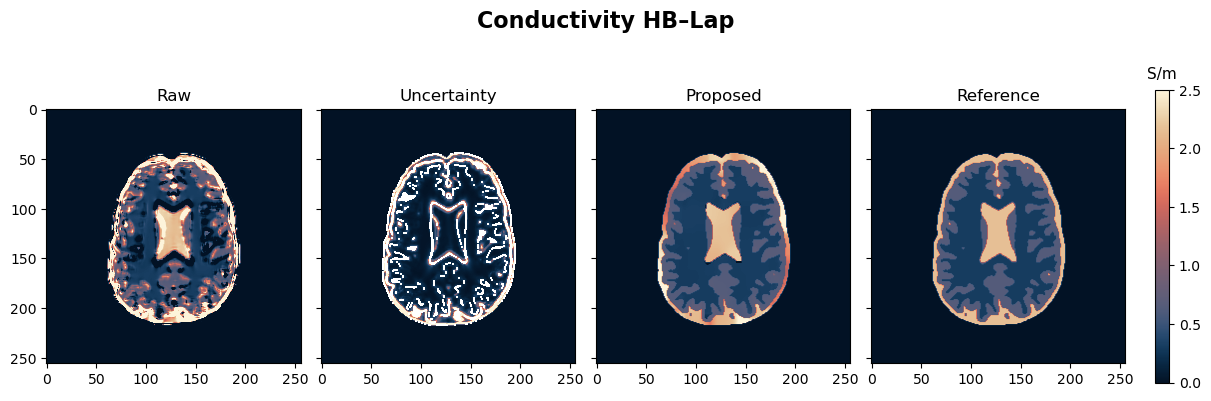

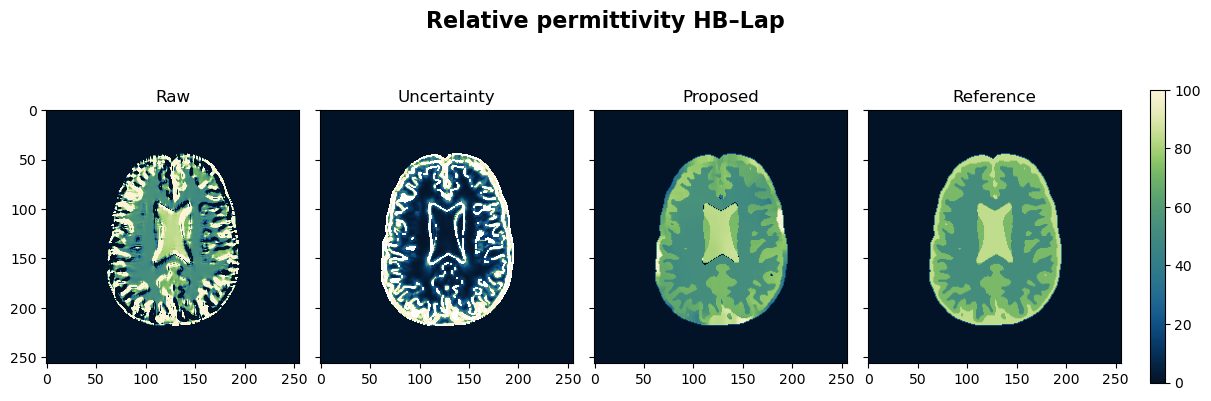

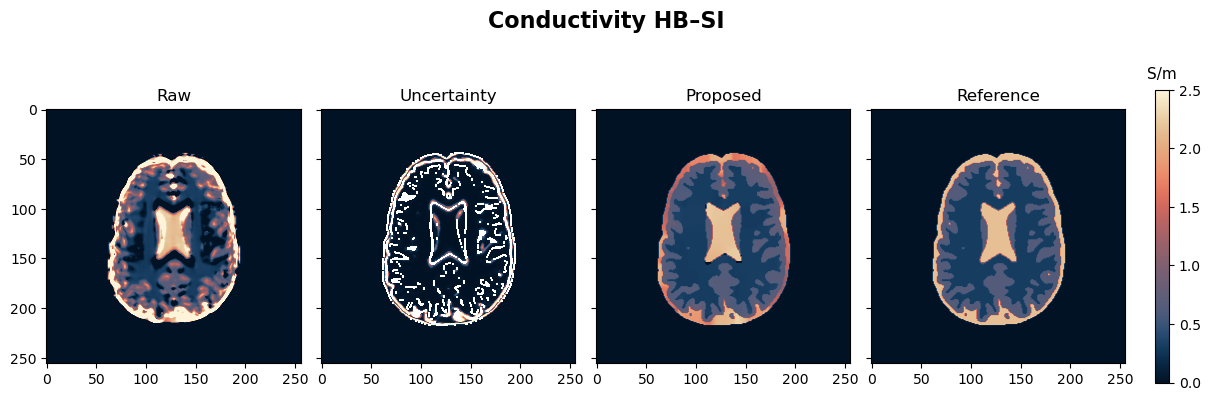

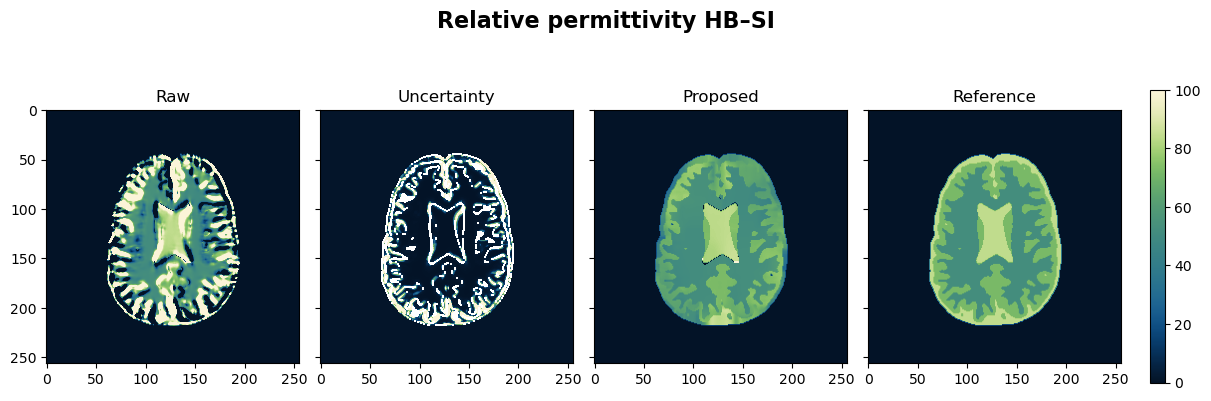

In [6]:
from cmcrameri.cm import lipari as lipari
from cmcrameri.cm import navia as navia
import matplotlib.pyplot as plt


fig1, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_HB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_HB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_HB_Lap_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig1.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig1.suptitle("Conductivity HB–Lap", fontsize=16, fontweight="bold")
plt.show()


fig2, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(epsilon_HB_Lap[..., k0], vmin=0, vmax=100, cmap=navia)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_epsilon_HB_Lap[..., k0], vmin=0, vmax=100, cmap=navia)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(epsilon_HB_Lap_f_min_unc[..., k0], vmin=0, vmax=100, cmap=navia)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(perm[..., k0], vmin=0, vmax=100, cmap=navia)
axs[3].set_title(f"Reference")

fig2.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
fig2.suptitle("Relative permittivity HB–Lap", fontsize=16, fontweight="bold")
plt.show()



fig3, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_HB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_HB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_HB_SI_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig3.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig3.suptitle("Conductivity HB–SI", fontsize=16, fontweight="bold")
plt.show()


fig4, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(epsilon_HB_SI[..., k0], vmin=0, vmax=100, cmap=navia)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_epsilon_HB_SI[..., k0], vmin=0, vmax=100, cmap=navia)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(epsilon_HB_SI_f_min_unc[..., k0], vmin=0, vmax=100, cmap=navia)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(perm[..., k0], vmin=0, vmax=100, cmap=navia)
axs[3].set_title(f"Reference")

fig4.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
fig4.suptitle("Relative permittivity HB–SI", fontsize=16, fontweight="bold")
plt.show()



### Run PB-Lap and PB-SI pipelines

In [7]:
Ref=segmentation
fit_kernel_size=[3,3,3]
int_kernel_size=[3,3,3]
post_processing_ksize=[21,21,21]
ROI =segmentation>0

sigma_PB_Lap, unc_sigma_PB_Lap, sigma_PB_Lap_f_min_unc= PB_Lap(ph_trsc*2, Ref, fit_kernel_size, post_processing_ksize, ROI, vs)
sigma_PB_SI, unc_sigma_PB_SI, sigma_PB_SI_f_min_unc= PB_SI (ph_trsc*2, Ref, fit_kernel_size, int_kernel_size,post_processing_ksize, ROI, vs)

Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [00:29<00:00, 56036.57it/s]


Elapsed time: 33.46 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:13<00:00, 22766.62it/s]


Elapsed time: 74.50 seconds
Number of CPU cores available and used: 12
Stage 1/2: fitting q=[c1,c3,c6] and covariance


...

Stage 2/2: phase surface integral + UQ


Phase SI-EPT + UQ: 100%|██████████████████████████████| 1672603/1672603 [00:15<00:00, 107605.01it/s]


Elapsed time: 68.42 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:13<00:00, 22621.63it/s]


Elapsed time: 75.03 seconds


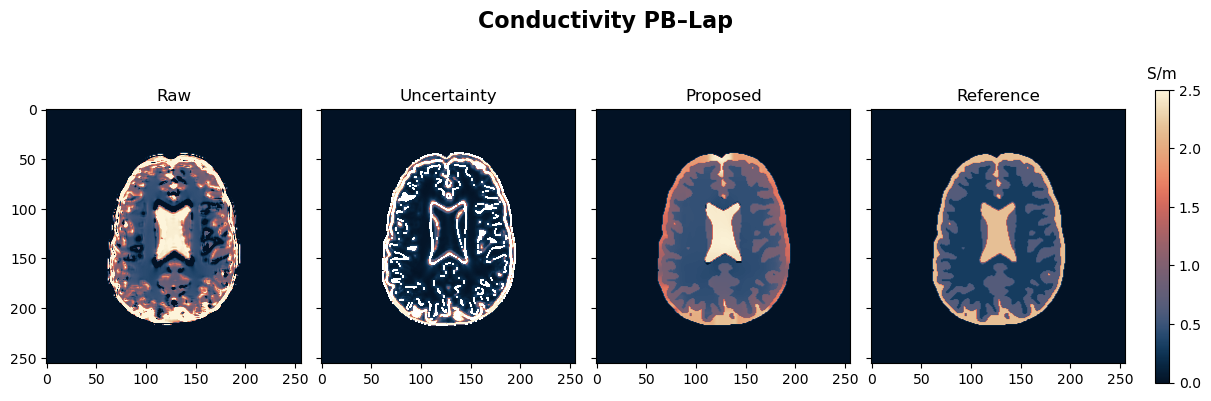

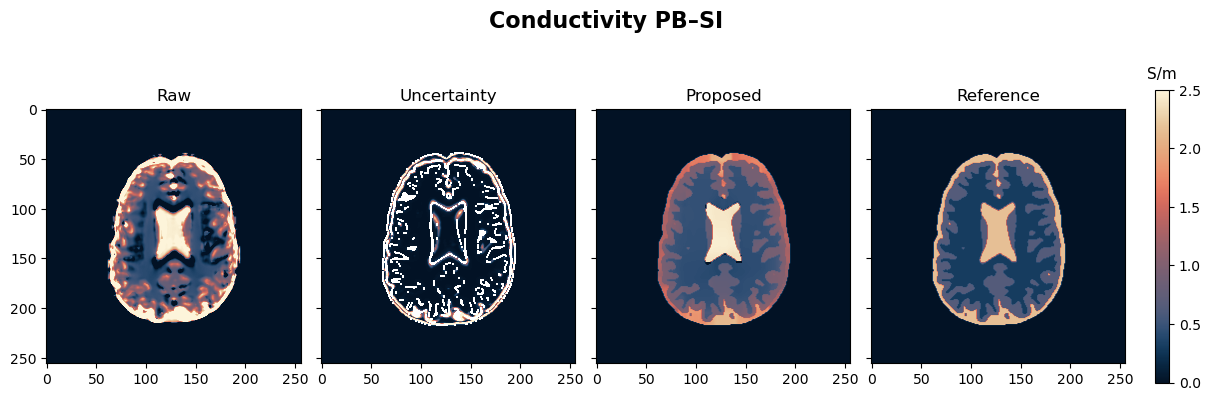

In [8]:
from cmcrameri.cm import lipari as lipari
from cmcrameri.cm import navia as navia
import matplotlib.pyplot as plt


fig5, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_PB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_PB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_PB_Lap_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig5.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig5.suptitle("Conductivity PB–Lap", fontsize=16, fontweight="bold")
plt.show()


fig6, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_PB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_PB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_PB_SI_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig6.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig6.suptitle("Conductivity PB–SI", fontsize=16, fontweight="bold")
plt.show()

## 5. B Simulated Brain without tumor with noise

### Import the dataset B: 

In [9]:
# Replace your dataset B path here:
path_dataset_B="/home/he/data/MREPTguideline/1 Input Datasets for your recon method/B Simulated Brain without tumor with noise/dataset_reference.mat"

import scipy
import numpy as np
data = scipy.io.loadmat(path_dataset_B, simplify_cells=True)


for field_name, field_data in data.items():
    if isinstance(field_data, np.ndarray):
        print(
            f"{field_name:20s}: "
            f"shape={field_data.shape}, dtype={field_data.dtype}"
        )
    else:
        print(f"{field_name:20s}: type={type(field_data)}")

globals().update(data)

__header__          : type=<class 'bytes'>
__version__         : type=<class 'str'>
__globals__         : type=<class 'list'>
b1p_mag             : shape=(256, 256, 160), dtype=float64
cond                : shape=(256, 256, 160), dtype=float64
cond_ref            : shape=(3,), dtype=float64
perm                : shape=(256, 256, 160), dtype=float64
perm_ref            : shape=(3,), dtype=uint8
ph_trsc             : shape=(256, 256, 160), dtype=float64
segmentation        : shape=(256, 256, 160), dtype=uint8
smag                : shape=(256, 256, 160), dtype=float64
tissue_names        : shape=(3,), dtype=object
vs                  : shape=(3,), dtype=float64


### Run HB-Lap and HB-SI pipelines

In [10]:
B= b1p_mag *np.exp(1j*ph_trsc)
Ref=segmentation
fit_kernel_size=[11,11,11]
int_kernel_size=[11,11,11]
post_processing_ksize=[21,21,21]
ROI =segmentation>0

sigma_HB_Lap, unc_sigma_HB_Lap, sigma_HB_Lap_f_min_unc, epsilon_HB_Lap, unc_epsilon_HB_Lap, epsilon_HB_Lap_f_min_unc= HB_Lap(B, Ref, fit_kernel_size, post_processing_ksize, ROI, vs)
sigma_HB_SI, unc_sigma_HB_SI, sigma_HB_SI_f_min_unc, epsilon_HB_SI, unc_epsilon_HB_SI, epsilon_HB_SI_f_min_unc= HB_SI (B, Ref, fit_kernel_size, int_kernel_size,post_processing_ksize, ROI, vs)

Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:40<00:00, 16625.91it/s]


Elapsed time: 103.88 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:11<00:00, 23265.16it/s]


Elapsed time: 72.92 seconds
Number of CPU cores available and used: 12
Processing...


...

Elapsed time: 215.48 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:11<00:00, 23327.83it/s]


Elapsed time: 72.75 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:11<00:00, 23469.62it/s]


Elapsed time: 72.27 seconds


#### Displaying uqEPT reconstruction against the reference maps

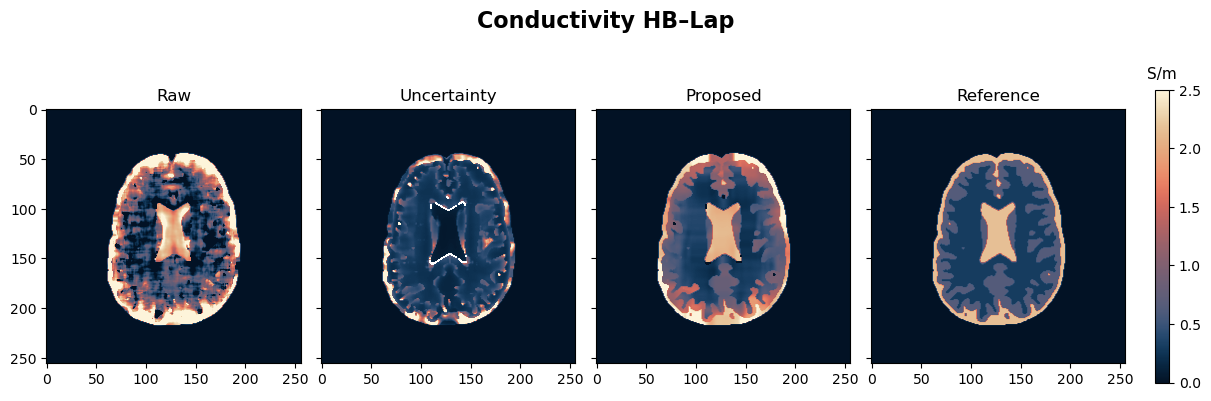

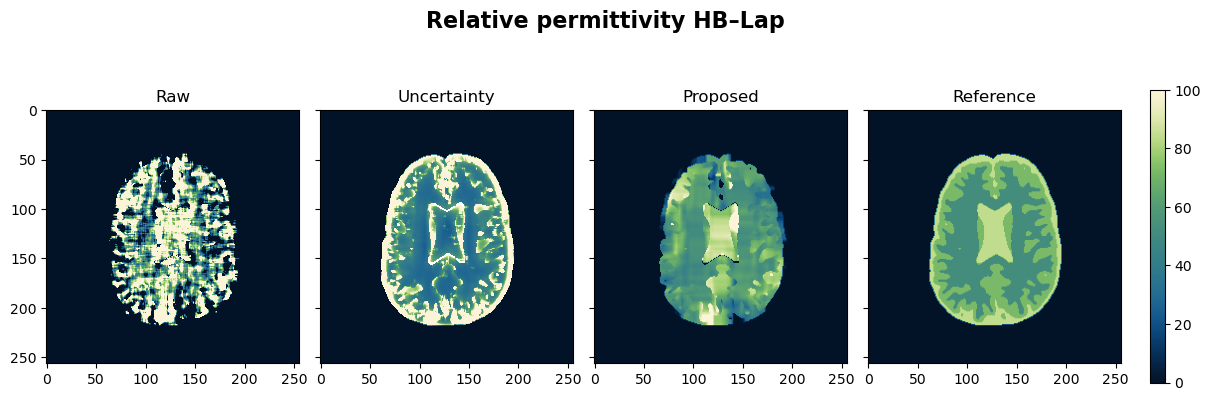

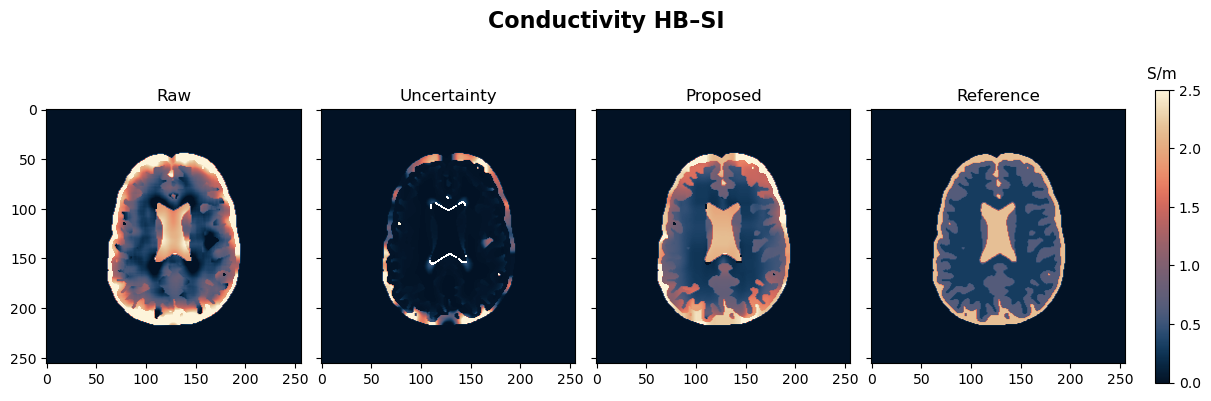

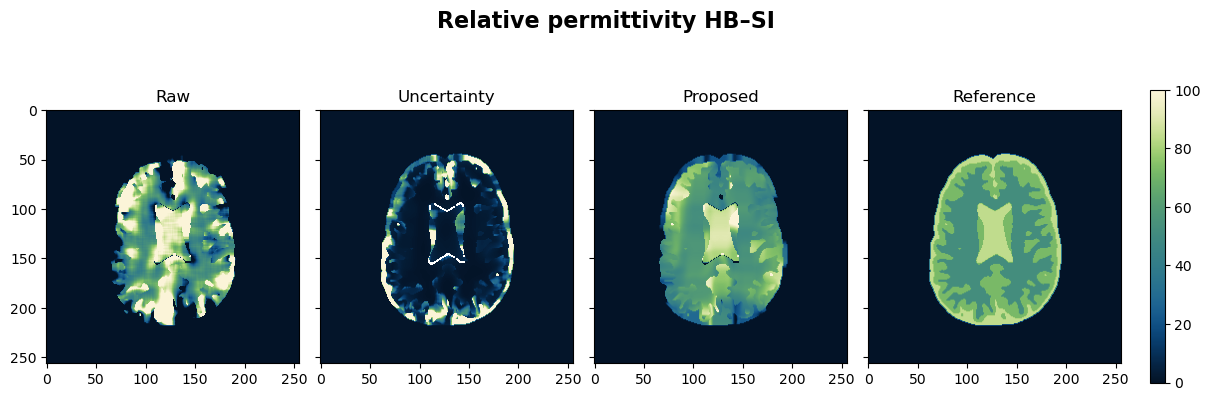

In [11]:
from cmcrameri.cm import lipari as lipari
from cmcrameri.cm import navia as navia
import matplotlib.pyplot as plt


fig7, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_HB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_HB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_HB_Lap_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig7.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig7.suptitle("Conductivity HB–Lap", fontsize=16, fontweight="bold")
plt.show()


fig8, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(epsilon_HB_Lap[..., k0], vmin=0, vmax=100, cmap=navia)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_epsilon_HB_Lap[..., k0], vmin=0, vmax=100, cmap=navia)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(epsilon_HB_Lap_f_min_unc[..., k0], vmin=0, vmax=100, cmap=navia)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(perm[..., k0], vmin=0, vmax=100, cmap=navia)
axs[3].set_title(f"Reference")

fig8.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
fig8.suptitle("Relative permittivity HB–Lap", fontsize=16, fontweight="bold")
plt.show()



fig9, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_HB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_HB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_HB_SI_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig9.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig9.suptitle("Conductivity HB–SI", fontsize=16, fontweight="bold")
plt.show()


fig10, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(epsilon_HB_SI[..., k0], vmin=0, vmax=100, cmap=navia)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_epsilon_HB_SI[..., k0], vmin=0, vmax=100, cmap=navia)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(epsilon_HB_SI_f_min_unc[..., k0], vmin=0, vmax=100, cmap=navia)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(perm[..., k0], vmin=0, vmax=100, cmap=navia)
axs[3].set_title(f"Reference")

fig10.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
fig10.suptitle("Relative permittivity HB–SI", fontsize=16, fontweight="bold")
plt.show()

### Run PB-Lap and PB-SI pipelines

In [12]:
Ref=segmentation
fit_kernel_size=[11,11,11]
int_kernel_size=[11,11,11]
post_processing_ksize=[21,21,21]
ROI =segmentation>0

sigma_PB_Lap, unc_sigma_PB_Lap, sigma_PB_Lap_f_min_unc= PB_Lap(ph_trsc*2, Ref, fit_kernel_size, post_processing_ksize, ROI, vs)
sigma_PB_SI, unc_sigma_PB_SI, sigma_PB_SI_f_min_unc= PB_SI (ph_trsc*2, Ref, fit_kernel_size, int_kernel_size,post_processing_ksize, ROI, vs)

Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:31<00:00, 18309.25it/s]


Elapsed time: 94.11 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:11<00:00, 23463.33it/s]


Elapsed time: 72.34 seconds
Number of CPU cores available and used: 12
Stage 1/2: fitting q=[c1,c3,c6] and covariance


...

Stage 2/2: phase surface integral + UQ


Phase SI-EPT + UQ: 100%|███████████████████████████████| 1672603/1672603 [01:10<00:00, 23712.45it/s]


Elapsed time: 179.60 seconds
Number of CPU cores available and used: 12
Processing...


Processing Patches: 100%|██████████████████████████████| 1672603/1672603 [01:11<00:00, 23451.98it/s]


Elapsed time: 72.35 seconds


#### Displaying uqEPT reconstruction against the reference maps

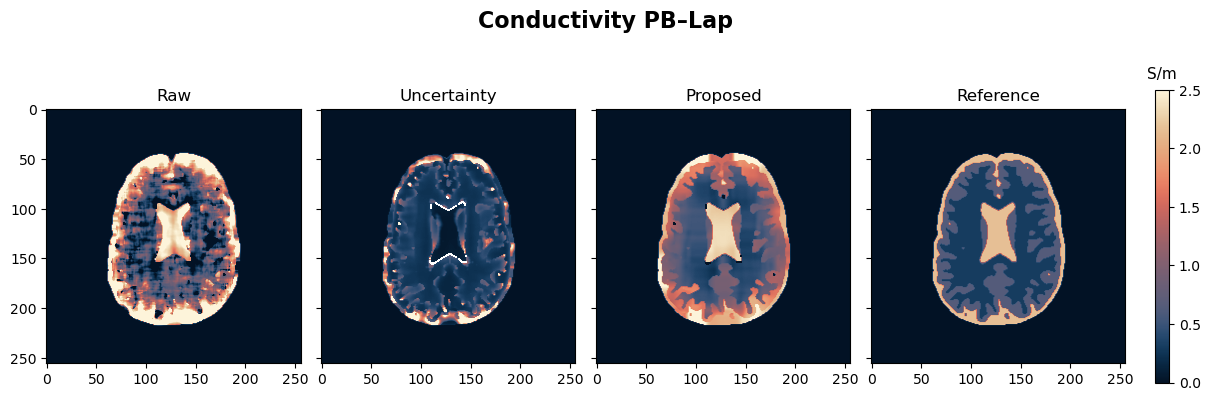

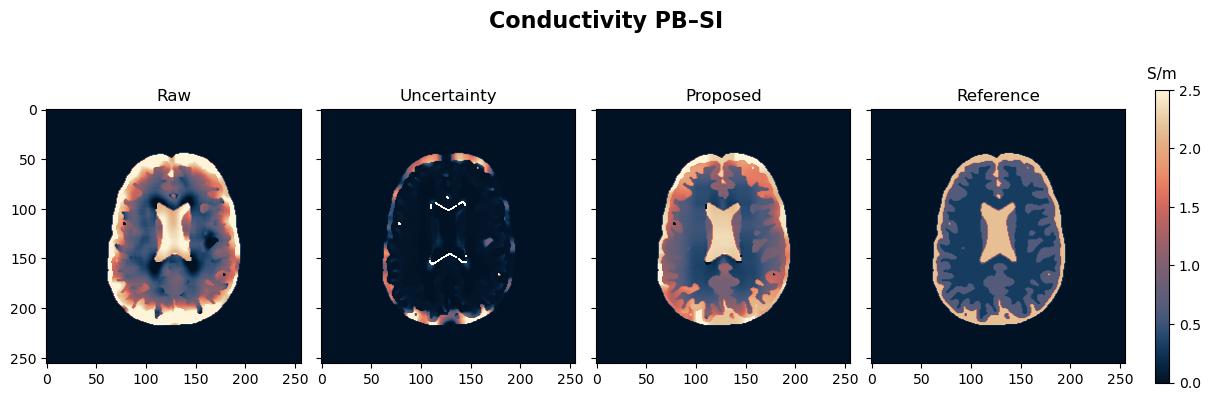

In [13]:
from cmcrameri.cm import lipari as lipari
from cmcrameri.cm import navia as navia
import matplotlib.pyplot as plt


fig11, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_PB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_PB_Lap[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_PB_Lap_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig11.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig11.suptitle("Conductivity PB–Lap", fontsize=16, fontweight="bold")
plt.show()


fig12, axs = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(12, 4.3), 
                         facecolor="white",layout="constrained")

k0 = cond.shape[2] // 2

axs[0].imshow(sigma_PB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[0].set_title(f"Raw")

axs[1].imshow(unc_sigma_PB_SI[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[1].set_title(f"Uncertainty")

axs[2].imshow(sigma_PB_SI_f_min_unc[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[2].set_title(f"Proposed")

im=axs[3].imshow(cond[..., k0], vmin=0, vmax=2.5, cmap=lipari)
axs[3].set_title(f"Reference")

cbar = fig12.colorbar(im, ax=axs, shrink=0.75, pad=0.02)
cbar.ax.set_title("S/m", fontsize=11, pad=8)
fig12.suptitle("Conductivity PB–SI", fontsize=16, fontweight="bold")
plt.show()